**IMDB Top 1000 Movies and TV Shows**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

os.makedirs('/content/drive/MyDrive/Analisis IMDB Top 1000', exist_ok=True)

print("Folder berhasil dibuat")

Folder berhasil dibuat


In [ ]:
import shutil

shutil.copy(
    '/content/imdb_top_1000.csv',
    '/content/drive/MyDrive/Analisis IMDB Top 1000/imdb_top_1000.csv'
)

print("File CSV berhasil disimpan ke Google Drive")

File CSV berhasil disimpan ke Google Drive


# Bagian Baru

1.Data Loading

Kode berikut digunakan untuk mengimpor library yang dibutuhkan, membaca dataset imdb_top_1000.csv, serta menampilkan ukuran, tipe data, dan contoh data awal.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

df = pd.read_csv("imdb_top_1000.csv")
print("Ukuran data (baris, kolom):", df.shape)
print(df.dtypes)
df.head()

Ukuran data (baris, kolom): (1000, 16)
Poster_Link       object
Series_Title      object
Released_Year     object
Certificate       object
Runtime           object
Genre             object
IMDB_Rating      float64
Overview          object
Meta_score       float64
Director          object
Star1             object
Star2             object
Star3             object
Star4             object
No_of_Votes        int64
Gross             object
dtype: object


,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


2.Data Cleaning

Kode berikut digunakan untuk membersihkan data, memperbaiki format kolom, menangani data tahun yang tidak valid, mengubah runtime dan gross menjadi numerik, memeriksa nilai kosong, duplikat, rentang nilai, dan outlier.

In [ ]:
# Samakan nama kolom ke huruf kecil dan buang kolom yang tidak berguna
df.columns = df.columns.str.strip().str.lower()
df = df.drop(columns=["poster_link"])

# Rapikan spasi pada kolom teks
kolom_teks = df.select_dtypes(include=["object", "string"]).columns
for k in kolom_teks:
    df[k] = df[k].str.strip()

# Temukan baris yang tahun rilisnya bukan angka 4 digit
salah_tahun = ~df["released_year"].str.fullmatch(r"\d{4}")
print("Baris dengan released_year tidak valid:")
print(df.loc[salah_tahun, ["series_title", "released_year", "certificate"]])

# "Apollo 13" tertukar: kolom tahun berisi 'PG' (seharusnya sertifikat).
# Perbaikan: pindahkan ke certificate, isi tahun dengan 1995.
for i in df.index[salah_tahun]:
    df.loc[i, "certificate"] = df.loc[i, "released_year"]
    df.loc[i, "released_year"] = "1995" if df.loc[i, "series_title"] == "Apollo 13" else np.nan
df["released_year"] = pd.to_numeric(df["released_year"], errors="coerce")

# Runtime: "142 min" -> 142
df["runtime_min"] = df["runtime"].str.extract(r"(\d+)")[0].astype(float)
df = df.drop(columns=["runtime"])

# Gross: "28,341,469" -> 28341469.0
df["gross"] = pd.to_numeric(df["gross"].str.replace(",", "", regex=False), errors="coerce")

# Nilai kosong (tidak dihapus; diisi di dalam pipeline model)
kosong = df.isnull().sum()
print("\nNilai kosong per kolom:")
print(pd.DataFrame({"jumlah": kosong, "persen": (kosong / len(df) * 100).round(1)})[kosong > 0])

# Duplikat
print("\nBaris duplikat penuh:", df.duplicated().sum())
print("Duplikat berdasarkan judul + tahun:", df.duplicated(subset=["series_title", "released_year"]).sum())
df = df.drop_duplicates().reset_index(drop=True)

# Validasi rentang nilai
print("\nValidasi rentang:")
print("  rating di luar 0-10      :", ((df.imdb_rating < 0) | (df.imdb_rating > 10)).sum())
print("  meta_score di luar 0-100 :", ((df.meta_score < 0) | (df.meta_score > 100)).sum())
print("  runtime <= 0             :", (df.runtime_min <= 0).sum())
print("  votes <= 0               :", (df.no_of_votes <= 0).sum())

# Outlier IQR (hanya dilaporkan, tidak dihapus)
print("\nLaporan outlier (aturan IQR):")
for k in ["imdb_rating", "meta_score", "runtime_min", "no_of_votes", "gross"]:
    q1, q3 = df[k].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[k] < q1 - 1.5 * iqr) | (df[k] > q3 + 1.5 * iqr)).sum()
    print(f"  {k}: {n_out} outlier")

print("\nUkuran data setelah cleaning:", df.shape)

Baris dengan released_year tidak valid:
    series_title released_year certificate
966    Apollo 13            PG           U

Nilai kosong per kolom:
             jumlah  persen
certificate     101    10.1
meta_score      157    15.7
gross           169    16.9

Baris duplikat penuh: 0
Duplikat berdasarkan judul + tahun: 0

Validasi rentang:
  rating di luar 0-10      : 0
  meta_score di luar 0-100 : 0
  runtime <= 0             : 0
  votes <= 0               : 0

Laporan outlier (aturan IQR):
  imdb_rating: 13 outlier
  meta_score: 7 outlier
  runtime_min: 29 outlier
  no_of_votes: 67 outlier
  gross: 89 outlier

Ukuran data setelah cleaning: (1000, 15)


3.Transformasi Data

Kode berikut digunakan untuk membuat fitur baru seperti dekade film, transformasi log pada jumlah vote dan pendapatan, penanda data kosong, pengelompokan sertifikat, fitur genre, serta jumlah kata pada sinopsis.

In [ ]:
# Dekade rilis
df["decade"] = (df["released_year"] // 10 * 10).astype(int)

# Log untuk kolom yang sangat miring ke kanan
df["log_votes"] = np.log1p(df["no_of_votes"])
df["log_gross"] = np.log1p(df["gross"])

# Penanda nilai kosong
df["gross_missing"] = df["gross"].isnull().astype(int)
df["meta_missing"] = df["meta_score"].isnull().astype(int)

# Kelompokkan sertifikat usia menjadi grup yang lebih sedikit
peta_sertifikat = {
    "U": "U", "G": "U",
    "UA": "UA", "U/A": "UA",
    "PG": "PG", "GP": "PG", "TV-PG": "PG",
    "PG-13": "PG-13", "TV-14": "PG-13", "16": "PG-13",
    "A": "A", "R": "R", "TV-MA": "R",
    "Passed": "Passed/Approved", "Approved": "Passed/Approved",
}
df["certificate_group"] = df["certificate"].map(peta_sertifikat).fillna("Unknown")
print(df["certificate_group"].value_counts())

# Genre: kolom 0/1 per genre
df["genre_list"] = df["genre"].str.split(",").apply(lambda g: [x.strip() for x in g])
df["n_genres"] = df["genre_list"].apply(len)
hitung_genre = df["genre_list"].explode().value_counts()
genre_dipakai = hitung_genre[hitung_genre >= 30].index.tolist()
for g in genre_dipakai:
    df[f"genre_{g}"] = df["genre_list"].apply(lambda lst, g=g: int(g in lst))
kolom_genre = [f"genre_{g}" for g in genre_dipakai]
print("\nGenre yang dipakai:", genre_dipakai)

# Panjang sinopsis (jumlah kata)
df["overview_words"] = df["overview"].str.split().str.len()

df[["series_title", "imdb_rating", "decade", "runtime_min", "log_votes",
    "log_gross", "certificate_group", "n_genres"]].head()

certificate_group
U                  245
A                  197
UA                 176
R                  147
Unknown            102
PG-13               45
Passed/Approved     45
PG                  43
Name: count, dtype: int64

Genre yang dipakai: ['Drama', 'Comedy', 'Crime', 'Adventure', 'Action', 'Thriller', 'Romance', 'Biography', 'Mystery', 'Animation', 'Sci-Fi', 'Fantasy', 'History', 'Family', 'War', 'Music', 'Horror']


,series_title,imdb_rating,decade,runtime_min,log_votes,log_gross,certificate_group,n_genres
0,The Shawshank Redemption,9.3,1990,142.0,14.666990,17.159837,A,1
1,The Godfather,9.2,1970,175.0,14.298164,18.720537,A,2
2,The Dark Knight,9.0,2000,152.0,14.649824,20.097513,UA,3
3,The Godfather: Part II,9.0,1970,202.0,13.937687,17.863811,A,2
4,12 Angry Men,9.0,1950,96.0,13.444224,15.287983,U,2


4.EDA, bagian Univariate

Kode berikut digunakan untuk melihat statistik dasar dan distribusi masing-masing variabel, termasuk rating, durasi, meta score, jumlah vote, pendapatan, tahun rilis, genre, sertifikat, dekade, dan nilai kosong.

       imdb_rating  released_year  runtime_min  meta_score  no_of_votes         gross  n_genres  overview_words
count      1000.00        1000.00      1000.00      843.00      1000.00  8.310000e+02   1000.00         1000.00
mean          7.95        1991.22       122.89       77.97    273692.91  6.803475e+07      2.54           25.00
std           0.28          23.29        28.09       12.38    327372.70  1.097500e+08      0.68            7.75
min           7.60        1920.00        45.00       28.00     25088.00  1.305000e+03      1.00            8.00
25%           7.70        1976.00       103.00       70.00     55526.25  3.253559e+06      2.00           19.00
50%           7.90        1999.00       119.00       79.00    138548.50  2.353089e+07      3.00           24.00
75%           8.10        2009.00       137.00       87.00    374161.25  8.075089e+07      3.00           30.00
max           9.30        2020.00       321.00      100.00   2343110.00  9.366622e+08      3.00         

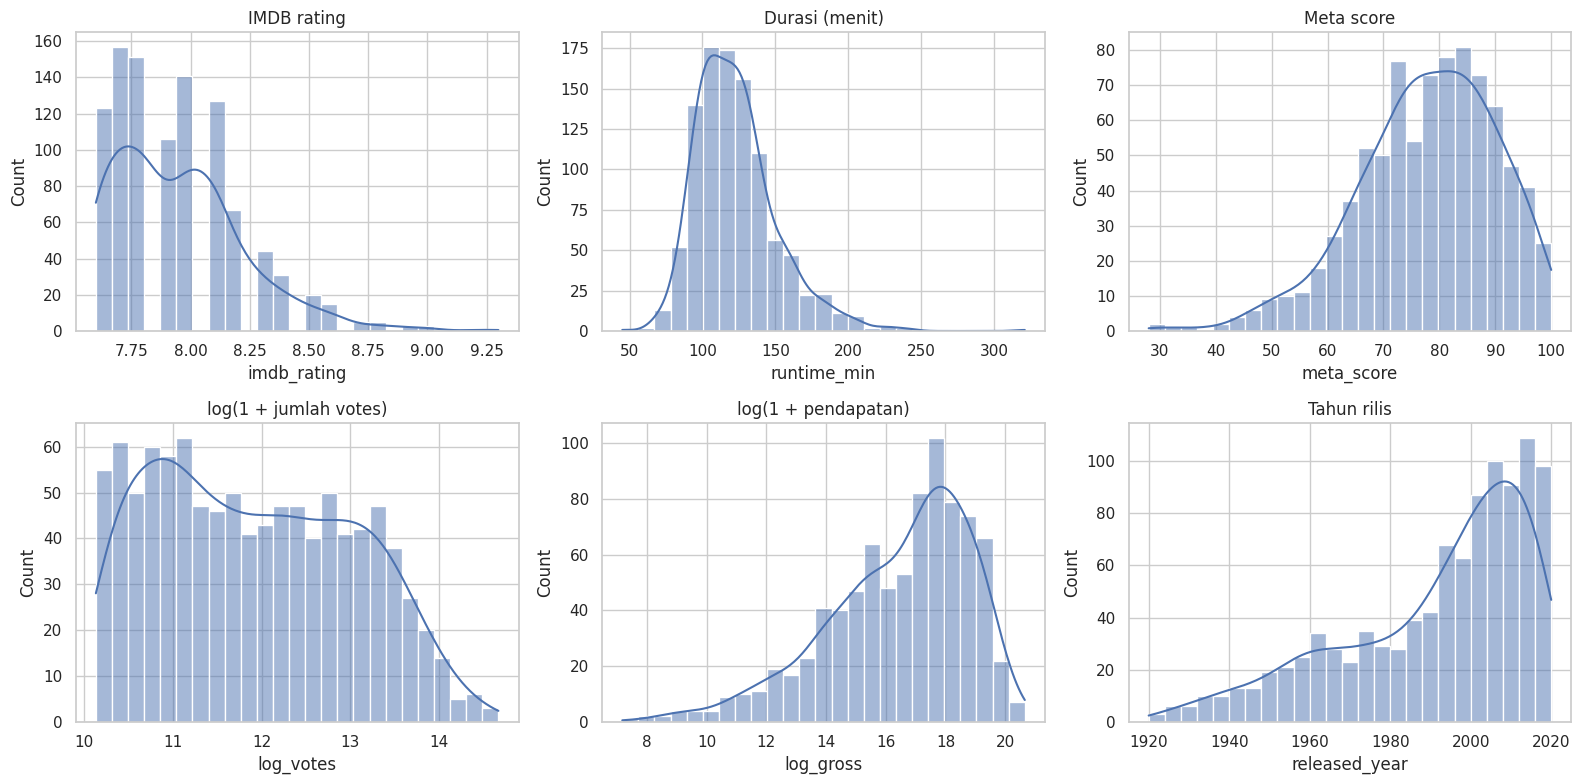

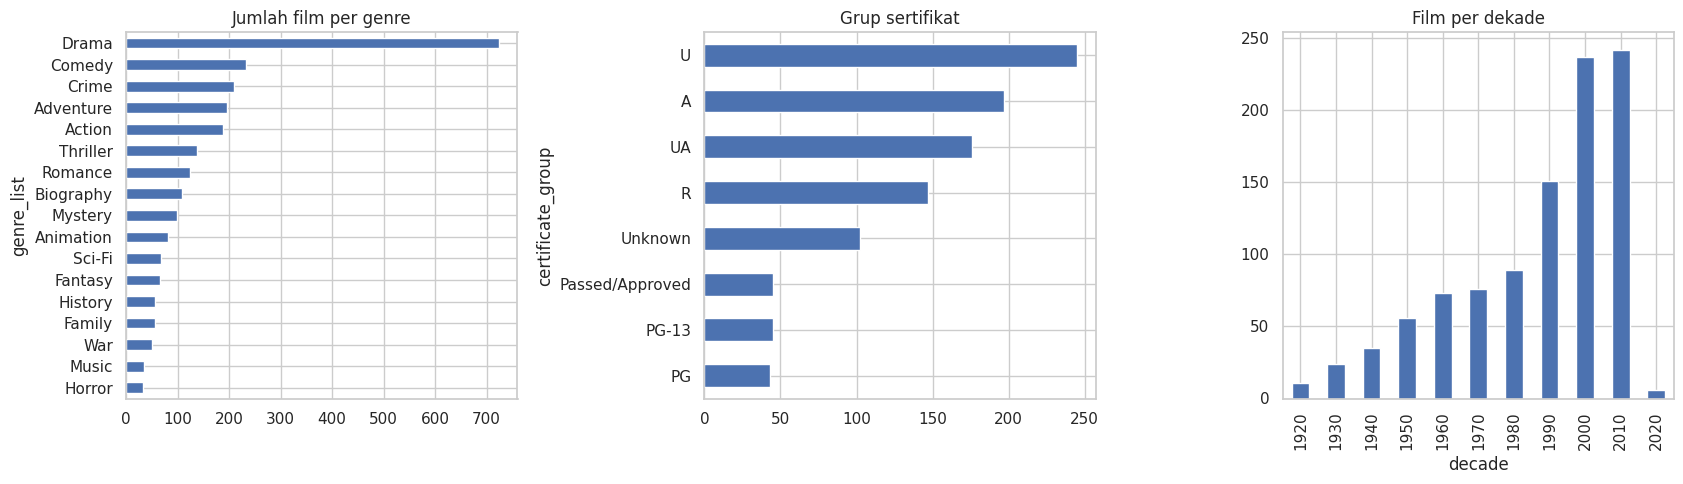

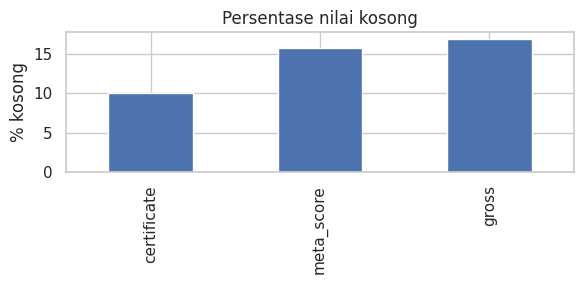

In [ ]:
kolom_numerik = ["released_year", "runtime_min", "meta_score", "no_of_votes",
                 "gross", "n_genres", "overview_words"]
print(df[["imdb_rating"] + kolom_numerik].describe().round(2))
print("\nKemiringan (skewness) rating:", round(df["imdb_rating"].skew(), 2))

# Distribusi variabel numerik utama
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (k, judul) in zip(axes.flat, [
        ("imdb_rating", "IMDB rating"), ("runtime_min", "Durasi (menit)"),
        ("meta_score", "Meta score"), ("log_votes", "log(1 + jumlah votes)"),
        ("log_gross", "log(1 + pendapatan)"), ("released_year", "Tahun rilis")]):
    sns.histplot(df[k].dropna(), bins=25, kde=True, ax=ax)
    ax.set_title(judul)
plt.tight_layout(); plt.show()

# Jumlah film per genre, sertifikat, dan dekade
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
hitung_genre[hitung_genre >= 30].sort_values().plot(kind="barh", ax=axes[0], title="Jumlah film per genre")
df["certificate_group"].value_counts().sort_values().plot(kind="barh", ax=axes[1], title="Grup sertifikat")
df["decade"].value_counts().sort_index().plot(kind="bar", ax=axes[2], title="Film per dekade")
plt.tight_layout(); plt.show()

# Pola nilai kosong
plt.figure(figsize=(6, 3))
(df[["certificate", "meta_score", "gross"]].isnull().mean() * 100).plot(kind="bar")
plt.ylabel("% kosong"); plt.title("Persentase nilai kosong")
plt.tight_layout(); plt.show()

5.EDA, bagian Bivariate

Kode berikut digunakan untuk menganalisis hubungan antara imdb_rating dengan variabel lain melalui scatter plot, box plot, rata-rata rating per genre, rating sutradara, dan daftar film dengan rating tertinggi.

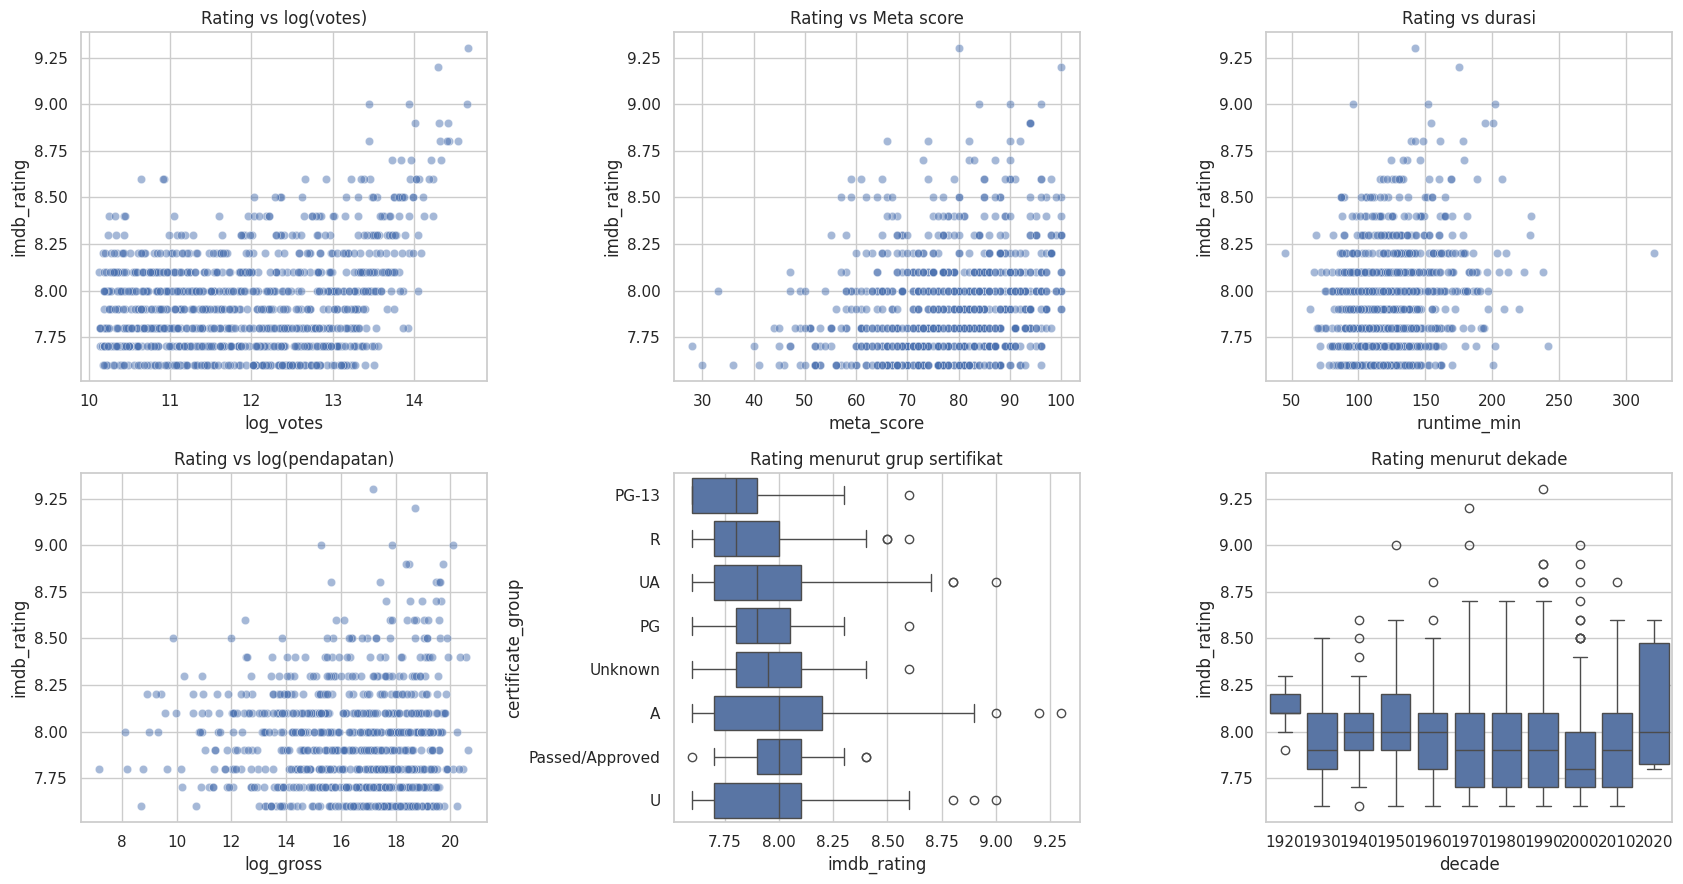

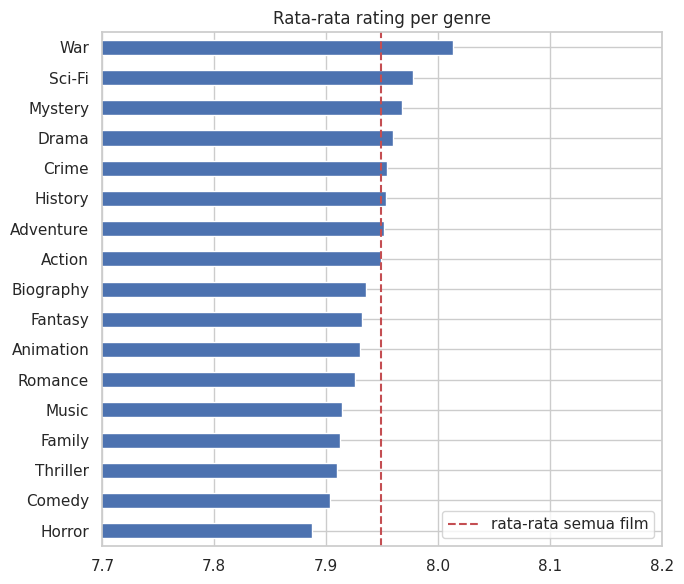

Sutradara dengan rata-rata rating tertinggi (minimal 4 film):
                      count  mean
director                         
Christopher Nolan         8  8.46
Francis Ford Coppola      5  8.40
Peter Jackson             5  8.40
Charles Chaplin           6  8.33
Sergio Leone              6  8.27
Stanley Kubrick           9  8.23
Akira Kurosawa           10  8.22
Frank Capra               4  8.20
Quentin Tarantino         8  8.18
Rajkumar Hirani           4  8.18

10 film dengan rating tertinggi:
                                 series_title  released_year  imdb_rating  no_of_votes
                     The Shawshank Redemption           1994          9.3      2343110
                                The Godfather           1972          9.2      1620367
                              The Dark Knight           2008          9.0      2303232
                       The Godfather: Part II           1974          9.0      1129952
                                 12 Angry Men           1957 

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

sns.scatterplot(data=df, x="log_votes", y="imdb_rating", alpha=0.5, ax=axes[0, 0])
axes[0, 0].set_title("Rating vs log(votes)")
sns.scatterplot(data=df, x="meta_score", y="imdb_rating", alpha=0.5, ax=axes[0, 1])
axes[0, 1].set_title("Rating vs Meta score")
sns.scatterplot(data=df, x="runtime_min", y="imdb_rating", alpha=0.5, ax=axes[0, 2])
axes[0, 2].set_title("Rating vs durasi")

sns.scatterplot(data=df, x="log_gross", y="imdb_rating", alpha=0.5, ax=axes[1, 0])
axes[1, 0].set_title("Rating vs log(pendapatan)")
urut_sert = df.groupby("certificate_group")["imdb_rating"].median().sort_values().index
sns.boxplot(data=df, y="certificate_group", x="imdb_rating", order=urut_sert, ax=axes[1, 1])
axes[1, 1].set_title("Rating menurut grup sertifikat")
sns.boxplot(data=df, x="decade", y="imdb_rating", ax=axes[1, 2])
axes[1, 2].set_title("Rating menurut dekade")
plt.tight_layout(); plt.show()

# Rata-rata rating per genre
rata_genre = pd.Series({g: df.loc[df[f"genre_{g}"] == 1, "imdb_rating"].mean() for g in genre_dipakai})
rata_genre.sort_values().plot(kind="barh", figsize=(7, 6), title="Rata-rata rating per genre")
plt.axvline(df["imdb_rating"].mean(), color="r", linestyle="--", label="rata-rata semua film")
plt.legend(); plt.xlim(7.7, 8.2); plt.tight_layout(); plt.show()

# Sutradara dengan rata-rata rating tertinggi (minimal 4 film)
sut = df.groupby("director")["imdb_rating"].agg(["count", "mean"])
print("Sutradara dengan rata-rata rating tertinggi (minimal 4 film):")
print(sut[sut["count"] >= 4].sort_values("mean", ascending=False).head(10).round(2))

print("\n10 film dengan rating tertinggi:")
print(df.nlargest(10, "imdb_rating")[["series_title", "released_year", "imdb_rating", "no_of_votes"]].to_string(index=False))

6.EDA, Korelasi

Kode berikut digunakan untuk melihat hubungan beberapa variabel numerik sekaligus menggunakan korelasi Spearman yang ditampilkan dalam bentuk heatmap.

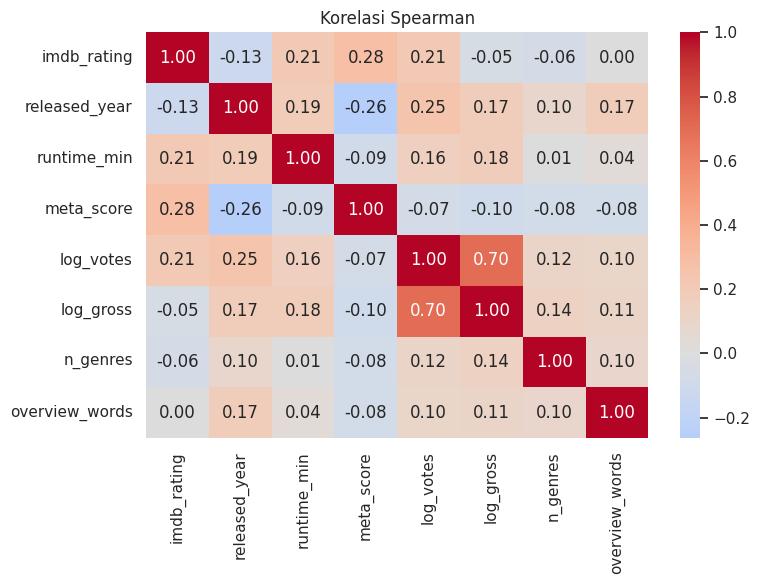

In [ ]:
kolom_korelasi = ["imdb_rating", "released_year", "runtime_min", "meta_score",
                  "log_votes", "log_gross", "n_genres", "overview_words"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[kolom_korelasi].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Korelasi Spearman")
plt.tight_layout(); plt.show()

7.EDA lanjutan (exda), uji statistik

Kode berikut digunakan untuk melakukan analisis statistik lanjutan menggunakan korelasi Spearman, Kruskal-Wallis, Mann-Whitney, koreksi Bonferroni, perbandingan film dengan gross kosong dan tidak kosong, serta interval kepercayaan 95%.

Korelasi Spearman dengan imdb_rating:
         fitur    n    rho p_value  signifikan
 released_year 1000 -0.127 <0.0001        True
   runtime_min 1000  0.212 <0.0001        True
    meta_score  843  0.285 <0.0001        True
     log_votes 1000  0.214 <0.0001        True
     log_gross  831 -0.050  0.1524       False
      n_genres 1000 -0.063  0.0481        True
overview_words 1000  0.003  0.9126       False

Kruskal-Wallis (lebih dari dua kelompok):
  certificate_group: H=33.96, p=<0.0001, epsilon^2=0.034, signifikan=True
  decade: H=39.95, p=<0.0001, epsilon^2=0.040, signifikan=True

Rating per genre vs film lain (Mann-Whitney):
    genre  n_film  selisih_rata2  rank_biserial p_value p_bonferroni  signifikan
      War      51          0.068          0.162  0.0496       0.8433       False
    Drama     724          0.037          0.077  0.0566       0.9620       False
   Sci-Fi      67          0.030          0.053  0.4668       1.0000       False
  Mystery      99          0.020   

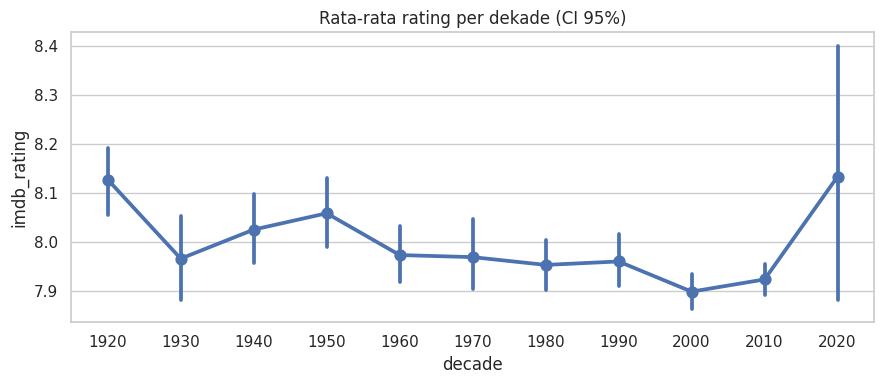

In [ ]:
def format_p(p):
    return "<0.0001" if p < 0.0001 else f"{p:.4f}"

# Korelasi Spearman antara rating dan tiap fitur numerik
baris = []
for k in ["released_year", "runtime_min", "meta_score", "log_votes", "log_gross",
          "n_genres", "overview_words"]:
    d = df[["imdb_rating", k]].dropna()
    rho, p = stats.spearmanr(d["imdb_rating"], d[k])
    baris.append({"fitur": k, "n": len(d), "rho": round(rho, 3),
                  "p_value": format_p(p), "signifikan": p < 0.05})
print("Korelasi Spearman dengan imdb_rating:")
print(pd.DataFrame(baris).to_string(index=False))

# Kruskal-Wallis: rating berbeda antar grup sertifikat / dekade?
print("\nKruskal-Wallis (lebih dari dua kelompok):")
for k in ["certificate_group", "decade"]:
    kelompok = [g["imdb_rating"].values for _, g in df.groupby(k)]
    H, p = stats.kruskal(*kelompok)
    eps2 = H / (len(df) - 1)
    print(f"  {k}: H={H:.2f}, p={format_p(p)}, epsilon^2={eps2:.3f}, signifikan={p < 0.05}")

# Mann-Whitney: tiap genre vs film lainnya (koreksi Bonferroni)
baris = []
for g in genre_dipakai:
    a = df.loc[df[f"genre_{g}"] == 1, "imdb_rating"]
    b = df.loc[df[f"genre_{g}"] == 0, "imdb_rating"]
    U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    baris.append({"genre": g, "n_film": len(a),
                  "selisih_rata2": round(a.mean() - b.mean(), 3),
                  "rank_biserial": round(2 * U / (len(a) * len(b)) - 1, 3),
                  "p_value": p})
tabel_genre = pd.DataFrame(baris)
tabel_genre["p_bonferroni"] = (tabel_genre["p_value"] * len(tabel_genre)).clip(upper=1)
tabel_genre["signifikan"] = tabel_genre["p_bonferroni"] < 0.05
tabel_genre["p_value"] = tabel_genre["p_value"].map(format_p)
tabel_genre["p_bonferroni"] = tabel_genre["p_bonferroni"].map(format_p)
print("\nRating per genre vs film lain (Mann-Whitney):")
print(tabel_genre.sort_values("selisih_rata2", ascending=False).to_string(index=False))

# Film dengan gross kosong vs ada
a = df.loc[df["gross_missing"] == 1, "imdb_rating"]
b = df.loc[df["gross_missing"] == 0, "imdb_rating"]
U, p = stats.mannwhitneyu(a, b)
print(f"\nGross kosong vs ada: selisih rata-rata rating = {a.mean() - b.mean():.3f}, p={format_p(p)}")

# Rata-rata rating per dekade (CI 95%)
plt.figure(figsize=(9, 4))
sns.pointplot(data=df, x="decade", y="imdb_rating", errorbar=("ci", 95), linestyles="-")
plt.title("Rata-rata rating per dekade (CI 95%)")
plt.tight_layout(); plt.show()

8.Data Splitting

Kode berikut digunakan untuk menentukan variabel target dan fitur, kemudian membagi data menjadi data latih (80%) dan data uji (20%) menggunakan train_test_split.

In [ ]:
TARGET = "imdb_rating"

fitur_numerik = ["released_year", "runtime_min", "meta_score", "log_votes",
                 "log_gross", "n_genres", "overview_words"]
fitur_nominal = ["certificate_group"]
fitur_biner = ["gross_missing", "meta_missing"] + kolom_genre

X = df[fitur_numerik + fitur_nominal + fitur_biner]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Jumlah fitur:", X.shape[1])
print("Data latih :", X_train.shape)
print("Data uji   :", X_test.shape)
print("Rata-rata rating (latih vs uji):", round(y_train.mean(), 3), "vs", round(y_test.mean(), 3))

Jumlah fitur: 27
Data latih : (800, 27)
Data uji   : (200, 27)
Rata-rata rating (latih vs uji): 7.953 vs 7.936


9.Modelling

Kode berikut digunakan untuk membuat preprocessing dan melatih beberapa model regresi, yaitu Ridge, Random Forest, dan Gradient Boosting. Pengisian nilai kosong dan scaling dilakukan di dalam pipeline untuk mencegah data leakage.

In [ ]:
# Pengisian nilai kosong dan scaling dilakukan di dalam pipeline
# agar hanya belajar dari data latih (mencegah kebocoran data).
preprocess = ColumnTransformer([
    ("numerik", Pipeline([("isi", SimpleImputer(strategy="median")),
                          ("skala", StandardScaler())]), fitur_numerik),
    ("nominal", OneHotEncoder(handle_unknown="ignore"), fitur_nominal),
    ("biner", "passthrough", fitur_biner),
])

model_kandidat = {
    "Ridge": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=5,
                                           random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.03,
                                                   max_depth=3, subsample=0.8, random_state=42),
}

pipeline_terlatih = {}
for nama, model in model_kandidat.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    pipeline_terlatih[nama] = pipe
    print("Model dilatih:", nama)

Model dilatih: Ridge
Model dilatih: Random Forest
Model dilatih: Gradient Boosting


10.Evaluasi

Kode berikut digunakan untuk membandingkan performa model menggunakan R², MAE, dan RMSE, memilih model terbaik berdasarkan Cross-Validation R², menganalisis residual, mengukur pentingnya fitur, dan menampilkan contoh hasil prediksi.

                     Model  CV R2  Train R2  Test R2  Test MAE  Test RMSE
Baseline (tebak rata-rata)    NaN       NaN   -0.004     0.212      0.254
                     Ridge  0.424     0.474    0.346     0.164      0.205
             Random Forest  0.539     0.797    0.470     0.144      0.184
         Gradient Boosting  0.598     0.801    0.470     0.144      0.184

Jarak besar antara Train R2 dan Test R2 menandakan overfitting.

Model terbaik: Gradient Boosting


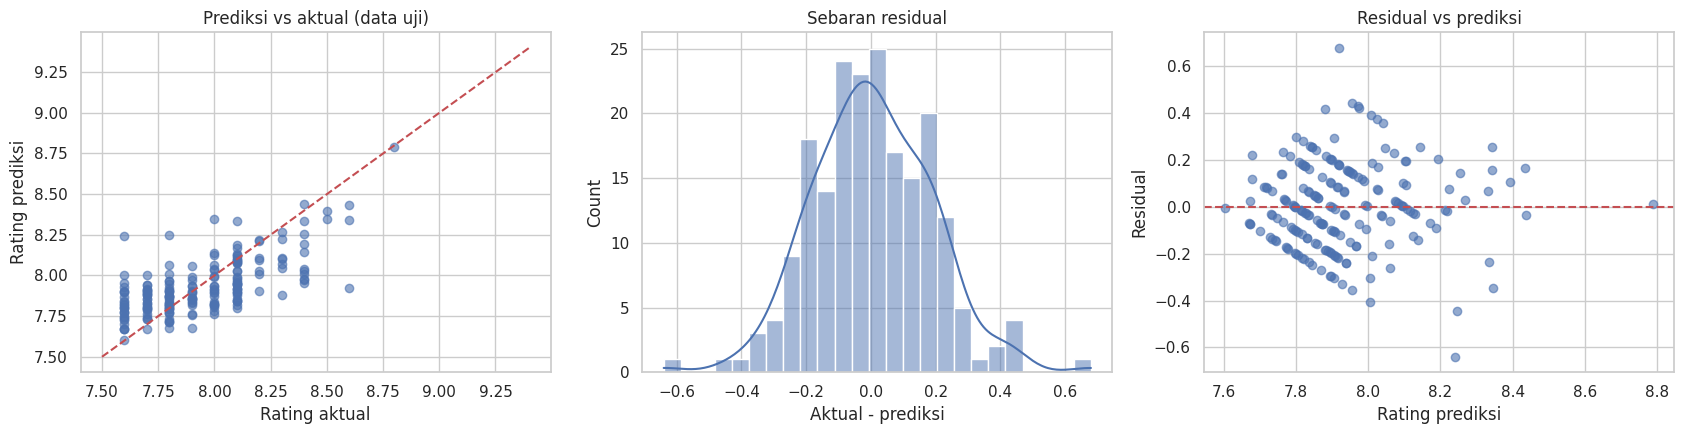

Residual: rata-rata=0.005, simpangan baku=0.184
Shapiro-Wilk: p=0.3326 (tampak normal)
Prediksi meleset <= 0.1 poin rating: 41.5%
Prediksi meleset <= 0.2 poin rating: 74.0%
Prediksi meleset <= 0.3 poin rating: 92.0%

Kesalahan menurut tingkat rating aktual:
                  jumlah  bias_rata2    mae
kelompok_rating                            
rendah (<=7.8)        90      -0.130  0.142
sedang (7.9-8.1)      79       0.075  0.116
tinggi (>8.1)         31       0.215  0.219
(bias positif = model cenderung memprediksi terlalu rendah)

15 fitur terpenting (penurunan R2 bila fitur diacak):
            fitur  penurunan_R2    std
        log_votes        1.1854 0.1126
        log_gross        0.2667 0.0435
    released_year        0.1763 0.0399
     meta_missing        0.0746 0.0209
       meta_score        0.0741 0.0188
      runtime_min        0.0636 0.0266
   genre_Thriller        0.0080 0.0040
     genre_Sci-Fi        0.0077 0.0026
certificate_group        0.0053 0.0070
      genre_Drama

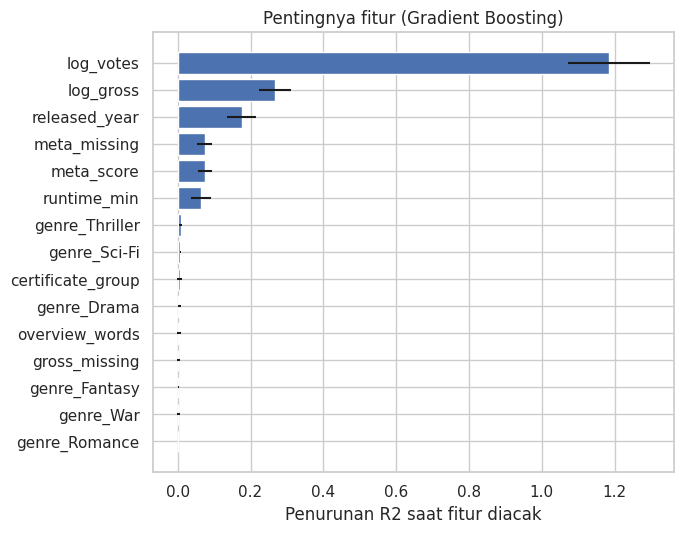

,judul,aktual,prediksi,selisih
0,Trois couleurs: Bleu,7.9,7.84,0.06
1,Captain America: The Winter Soldier,7.7,7.91,-0.21
2,Wreck-It Ralph,7.7,7.83,-0.13
3,The Sandlot,7.8,7.72,0.08
4,Gandhi,8.0,8.06,-0.06
5,Evil Dead II,7.8,7.81,-0.01
6,Little Miss Sunshine,7.8,7.86,-0.06
7,Children of Men,7.9,7.86,0.04
8,Repulsion,7.7,7.82,-0.12
9,Drishyam,8.2,8.10,0.10


In [ ]:
def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Perbandingan model
baseline = np.full(len(y_test), y_train.mean())
baris = [{"Model": "Baseline (tebak rata-rata)", "CV R2": np.nan, "Train R2": np.nan,
          "Test R2": r2_score(y_test, baseline),
          "Test MAE": mean_absolute_error(y_test, baseline),
          "Test RMSE": rmse(y_test, baseline)}]
for nama, pipe in pipeline_terlatih.items():
    cv = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2")
    pr_tr, pr_te = pipe.predict(X_train), pipe.predict(X_test)
    baris.append({"Model": nama, "CV R2": cv.mean(),
                  "Train R2": r2_score(y_train, pr_tr),
                  "Test R2": r2_score(y_test, pr_te),
                  "Test MAE": mean_absolute_error(y_test, pr_te),
                  "Test RMSE": rmse(y_test, pr_te)})
tabel = pd.DataFrame(baris).round(3)
print(tabel.to_string(index=False))
print("\nJarak besar antara Train R2 dan Test R2 menandakan overfitting.")

# Model terbaik dipilih dari CV R2 (data latih), bukan Test R2,
# supaya data uji tetap bersih untuk penilaian akhir.
tabel_model = tabel.iloc[1:].sort_values("CV R2", ascending=False)
nama_terbaik = tabel_model.iloc[0]["Model"]
pipe_terbaik = pipeline_terlatih[nama_terbaik]
pred = pipe_terbaik.predict(X_test)
residual = y_test.values - pred
print("\nModel terbaik:", nama_terbaik)

# Prediksi vs aktual dan residual
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(y_test, pred, alpha=0.6)
axes[0].plot([7.5, 9.4], [7.5, 9.4], "r--")
axes[0].set(xlabel="Rating aktual", ylabel="Rating prediksi", title="Prediksi vs aktual (data uji)")
sns.histplot(residual, bins=25, kde=True, ax=axes[1])
axes[1].set(xlabel="Aktual - prediksi", title="Sebaran residual")
axes[2].scatter(pred, residual, alpha=0.6)
axes[2].axhline(0, color="r", linestyle="--")
axes[2].set(xlabel="Rating prediksi", ylabel="Residual", title="Residual vs prediksi")
plt.tight_layout(); plt.show()

# Pemeriksaan residual dan ketelitian
_, p_sh = stats.shapiro(residual)
print(f"Residual: rata-rata={residual.mean():.3f}, simpangan baku={residual.std():.3f}")
print(f"Shapiro-Wilk: p={p_sh:.4f} ({'tampak normal' if p_sh > 0.05 else 'menyimpang dari normal'})")
for batas in (0.1, 0.2, 0.3):
    print(f"Prediksi meleset <= {batas} poin rating: {(np.abs(residual) <= batas).mean() * 100:.1f}%")

# Kesalahan per tingkat rating aktual
df_eval = pd.DataFrame({"aktual": y_test.values, "prediksi": pred, "residual": residual})
df_eval["kelompok_rating"] = pd.cut(df_eval["aktual"], [0, 7.8, 8.1, 10],
                                    labels=["rendah (<=7.8)", "sedang (7.9-8.1)", "tinggi (>8.1)"])
print("\nKesalahan menurut tingkat rating aktual:")
print(df_eval.groupby("kelompok_rating", observed=True)["residual"]
      .agg(jumlah="count", bias_rata2="mean", mae=lambda r: r.abs().mean()).round(3))
print("(bias positif = model cenderung memprediksi terlalu rendah)")

# Pentingnya fitur (permutation importance pada data uji)
hasil_perm = permutation_importance(pipe_terbaik, X_test, y_test, n_repeats=30,
                                    random_state=42, scoring="r2")
penting = pd.DataFrame({"fitur": X_test.columns,
                        "penurunan_R2": hasil_perm.importances_mean,
                        "std": hasil_perm.importances_std}).sort_values("penurunan_R2", ascending=False)
print("\n15 fitur terpenting (penurunan R2 bila fitur diacak):")
print(penting.head(15).round(4).to_string(index=False))

top = penting.head(15).iloc[::-1]
plt.figure(figsize=(7, 5.5))
plt.barh(top["fitur"], top["penurunan_R2"], xerr=top["std"])
plt.xlabel("Penurunan R2 saat fitur diacak")
plt.title(f"Pentingnya fitur ({nama_terbaik})")
plt.tight_layout(); plt.show()

# Contoh prediksi
contoh = pd.DataFrame({"judul": df.loc[X_test.index, "series_title"].values,
                       "aktual": y_test.values, "prediksi": pred.round(2)})
contoh["selisih"] = (contoh["aktual"] - contoh["prediksi"]).round(2)
contoh.head(10)